# AICS-202 | Laboratory 03
## Training Data Poisoning and Dataset Integrity
Course module: 3 | Suggested duration: 4 hours

**Objective:** measure how deliberately corrupted labels in a local training dataset affect a supervised model. This lab never changes external datasets or services.

**Scope:** simple random label corruption is an introductory poisoning simulation, not a realistic targeted backdoor.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


Corruption 0%: 0 labels changed | Clean test accuracy 0.962
Corruption 5%: 67 labels changed | Clean test accuracy 0.960
Corruption 10%: 135 labels changed | Clean test accuracy 0.958
Corruption 20%: 269 labels changed | Clean test accuracy 0.933


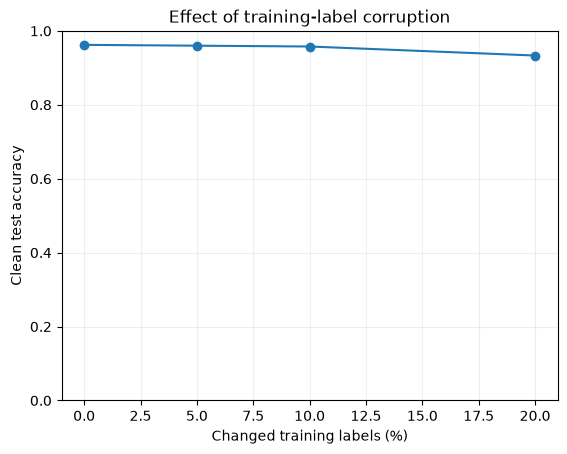

In [2]:
from sklearn.metrics import confusion_matrix
rng = np.random.default_rng(2026)
corruption_levels = [0.00, 0.05, 0.10, 0.20]
records = []
for fraction in corruption_levels:
    labels_changed = y_train.copy()
    n = round(len(labels_changed)*fraction)
    selected = rng.choice(len(labels_changed), size=n, replace=False)
    # Replace with a *different* label; this simulates integrity compromise.
    labels_changed[selected] = (labels_changed[selected] + rng.integers(1, 10, size=n)) % 10
    tested_model = build_model(X_train, labels_changed)
    accuracy = accuracy_score(y_test, tested_model.predict(X_test))
    records.append((fraction, n, accuracy))
    print(f'Corruption {fraction:.0%}: {n} labels changed | Clean test accuracy {accuracy:.3f}')
plt.plot([r[0]*100 for r in records], [r[2] for r in records], 'o-')
plt.xlabel('Changed training labels (%)'); plt.ylabel('Clean test accuracy')
plt.title('Effect of training-label corruption');plt.ylim(0,1);plt.grid(alpha=.2);plt.show()

Reference hash | y_train: ee47679cf3fee774 | y_test: 5a26fdbefc64ddd2

frac | n changed | verified changed | accuracy | train-label hash | test-label hash matches
0.00 | 0 | 0 | 0.9622 | ee47679cf3fee774 | True
0.05 | 67 | 67 | 0.9600 | c50002482df852c2 | True
0.10 | 135 | 135 | 0.9578 | 40ea3e37468733a0 | True
0.20 | 269 | 269 | 0.9333 | 19b7e73d459d276e | True


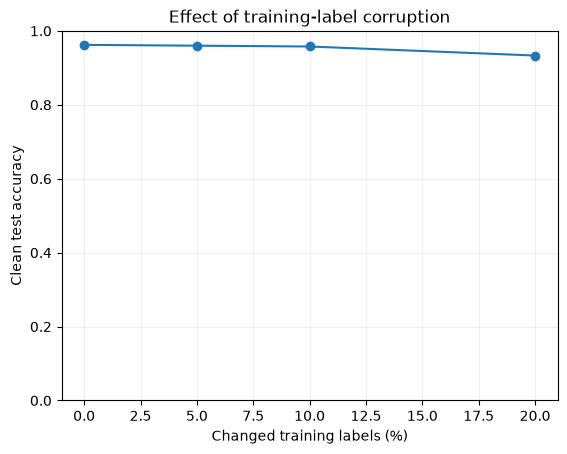


Mean accuracy over 10 seeds: [0.9622 0.9611 0.9531 0.9344]
Std  over 10 seeds:          [0.     0.006  0.0068 0.01  ]


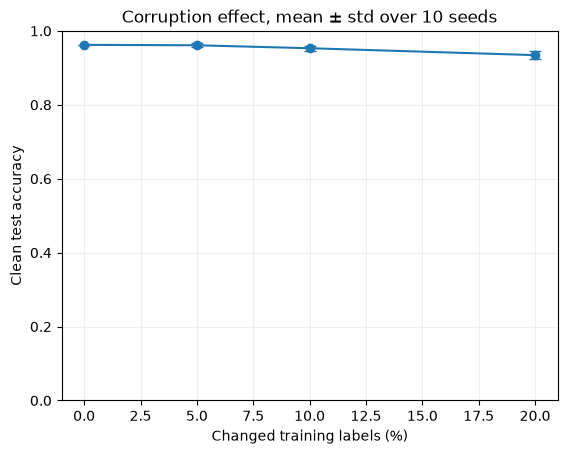

In [3]:
import os, csv, hashlib
os.makedirs('../results', exist_ok=True)

def sha(arr):
    return hashlib.sha256(np.ascontiguousarray(arr).tobytes()).hexdigest()[:16]

ref_train, ref_test = sha(y_train), sha(y_test)
print('Reference hash | y_train:', ref_train, '| y_test:', ref_test)

# 1) Same experiment as the notebook (same seed), with integrity checks
rng = np.random.default_rng(2026)
rows = []
print('\nfrac | n changed | verified changed | accuracy | train-label hash | test-label hash matches')
for fraction in [0.00, 0.05, 0.10, 0.20]:
    labels_changed = y_train.copy()
    n = round(len(labels_changed) * fraction)
    selected = rng.choice(len(labels_changed), size=n, replace=False)
    labels_changed[selected] = (labels_changed[selected] + rng.integers(1, 10, size=n)) % 10
    verified = int(np.sum(labels_changed != y_train))
    m = build_model(X_train, labels_changed)
    acc = accuracy_score(y_test, m.predict(X_test))
    h = sha(labels_changed)
    rows.append((fraction, n, verified, round(acc, 4), h, sha(y_test) == ref_test))
    print(f'{fraction:.2f} | {n} | {verified} | {acc:.4f} | {h} | {sha(y_test) == ref_test}')

with open('../results/lab03_results.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['fraction', 'labels_changed', 'verified_changed', 'clean_test_accuracy', 'train_label_hash', 'test_labels_unchanged'])
    w.writerows(rows)

plt.figure()
plt.plot([r[0] * 100 for r in rows], [r[3] for r in rows], 'o-')
plt.xlabel('Changed training labels (%)'); plt.ylabel('Clean test accuracy')
plt.title('Effect of training-label corruption'); plt.ylim(0, 1); plt.grid(alpha=.2)
plt.savefig('../results/lab03_corruption_curve.png', dpi=200); plt.show()

# 2) Optional noise check: repeat with 10 different seeds
levels = [0.00, 0.05, 0.10, 0.20]
runs = np.zeros((10, len(levels)))
for s in range(10):
    r = np.random.default_rng(1000 + s)
    for k, fr in enumerate(levels):
        lc = y_train.copy()
        n = round(len(lc) * fr)
        sel = r.choice(len(lc), size=n, replace=False)
        lc[sel] = (lc[sel] + r.integers(1, 10, size=n)) % 10
        runs[s, k] = accuracy_score(y_test, build_model(X_train, lc).predict(X_test))
print('\nMean accuracy over 10 seeds:', np.round(runs.mean(axis=0), 4))
print('Std  over 10 seeds:         ', np.round(runs.std(axis=0), 4))

plt.figure()
plt.errorbar([l * 100 for l in levels], runs.mean(axis=0), yerr=runs.std(axis=0), fmt='o-', capsize=4)
plt.xlabel('Changed training labels (%)'); plt.ylabel('Clean test accuracy')
plt.title('Corruption effect, mean ± std over 10 seeds'); plt.ylim(0, 1); plt.grid(alpha=.2)
plt.savefig('../results/lab03_corruption_10seeds.png', dpi=200); plt.show()

### Part B - Create a data integrity checklist
Prepare a controls table for dataset provenance, cryptographic hashes, label audits, role-restricted writes, staged approval, and anomaly review.

**Student exercises:**
- Explain why training data is a security asset.
- Compare control results and explain any non-monotonic accuracy changes.
- Propose three technical and two procedural safeguards.

**Deliverables:** plot, results table, explanation and a signed-off integrity checklist for this hypothetical dataset.